# Activity No. 1: Machine Learning Classification and Regression

**Course:** Artificial Intelligence / Machine Learning  
**Application:** E-commerce Customer Analytics  
**Tasks:** Predict customer purchase (classification) and estimate customer spending (regression).

> **Dataset note:** This notebook generates a reproducible *synthetic* dataset for demonstration. If your instructor requires a real-world dataset, replace the data-generation cell with the approved dataset and document its source.

#Student Deatils
- Name: Krishnakant Kolnure                     
- Div - A      Batch - A1          
- Programme: B.Tech – Computer Engineering
Year: Third Year (T.Y. B.Tech)
- College: MIT Academy of Engineering (MITAOE), Alandi, Pune
Academic Year: 2025–2026               
- Course: Artificial Intelligence / Machine Learning
Activity No.: 1

## Aim
To implement, evaluate, and compare classification and regression models using a machine-learning workflow.

## Learning objectives
- Explore and prepare customer data.
- Split data into training and testing sets.
- Train multiple classification and regression models.
- Evaluate models with appropriate metrics and visualizations.
- Interpret results and make a sample prediction.


## 1. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Generate the sample customer dataset

In [ ]:
n = 1500

df = pd.DataFrame({
    "age": np.random.randint(18, 66, n),
    "annual_income": np.random.randint(20000, 150001, n),
    "website_visits": np.random.randint(1, 30, n),
    "time_on_site": np.random.uniform(1, 30, n).round(2),
    "previous_purchases": np.random.randint(0, 20, n),
    "discount_used": np.random.randint(0, 2, n),
    "device": np.random.choice(["Mobile", "Desktop", "Tablet"], n)
})

# Create a purchase probability from behavior-related features.
purchase_score = (
    -2.0
    + 0.035 * df["website_visits"]
    + 0.07 * df["time_on_site"]
    + 0.12 * df["previous_purchases"]
    + 0.6 * df["discount_used"]
    + 0.000008 * df["annual_income"]
)
purchase_probability = 1 / (1 + np.exp(-purchase_score))
df["purchase"] = np.random.binomial(1, purchase_probability)

# Generate spending as a continuous target.
df["spending"] = (
    20
    + 0.15 * df["annual_income"]
    + 12 * df["previous_purchases"]
    + 5 * df["website_visits"]
    + 10 * df["discount_used"]
    + np.random.normal(0, 100, n)
).clip(lower=0).round(2)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1500, 9)


,age,annual_income,website_visits,time_on_site,previous_purchases,discount_used,device,purchase,spending
0,56,119804,16,21.50,11,1,Mobile,1,18085.59
1,46,26737,29,2.82,4,0,Tablet,0,4201.68
2,32,56062,1,25.34,19,0,Tablet,0,8598.51
3,60,74237,10,1.11,6,0,Desktop,0,11189.89
4,25,71571,18,8.16,9,1,Desktop,1,11082.42


## 3. Explore and validate the data

In [ ]:
print("Dataset information:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("missing_values"))

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\nPurchase class distribution:")
display(df["purchase"].value_counts().rename(index={0: "No purchase", 1: "Purchase"}))


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 1500 non-null   int64  
 1   annual_income       1500 non-null   int64  
 2   website_visits      1500 non-null   int64  
 3   time_on_site        1500 non-null   float64
 4   previous_purchases  1500 non-null   int64  
 5   discount_used       1500 non-null   int64  
 6   device              1500 non-null   object 
 7   purchase            1500 non-null   int64  
 8   spending            1500 non-null   float64
dtypes: float64(2), int64(6), object(1)
memory usage: 105.6+ KB

Missing values per column:


,missing_values
age,0
annual_income,0
website_visits,0
time_on_site,0
previous_purchases,0
discount_used,0
device,0
purchase,0
spending,0



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1500.0,NaN,NaN,NaN,41.587333,13.733127,18.0,29.75,42.0,53.0,65.0
annual_income,1500.0,NaN,NaN,NaN,86449.728667,37791.133273,20163.0,53024.5,86071.0,119867.5,149992.0
website_visits,1500.0,NaN,NaN,NaN,15.198667,8.334197,1.0,8.0,15.0,22.0,29.0
time_on_site,1500.0,NaN,NaN,NaN,15.35892,8.384688,1.0,8.1575,15.18,22.7,29.99
previous_purchases,1500.0,NaN,NaN,NaN,9.755333,5.749102,0.0,5.0,10.0,15.0,19.0
discount_used,1500.0,NaN,NaN,NaN,0.494,0.500131,0.0,0.0,0.0,1.0,1.0
device,1500,3,Desktop,516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purchase,1500.0,NaN,NaN,NaN,0.796667,0.402613,0.0,1.0,1.0,1.0,1.0
spending,1500.0,NaN,NaN,NaN,13184.097767,5669.314066,2970.65,8146.2475,13178.755,18199.4125,22824.3



Purchase class distribution:


,count
purchase,
Purchase,1195
No purchase,305


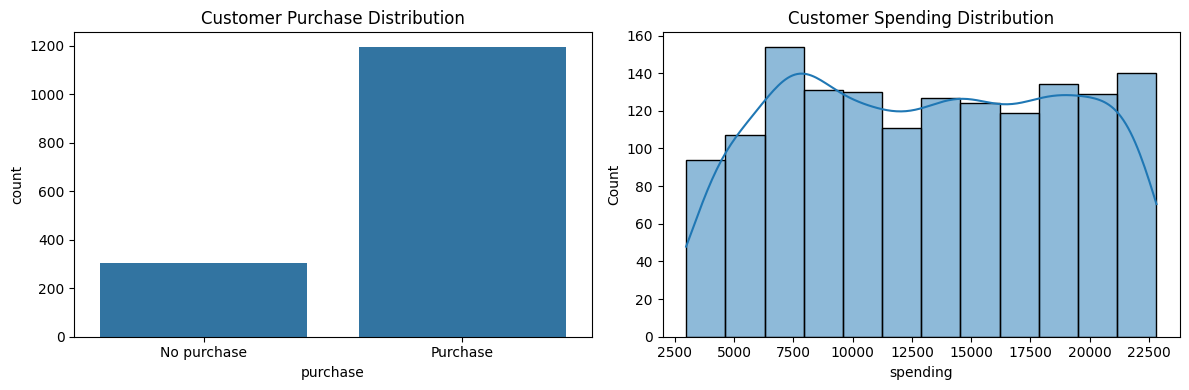

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="purchase", ax=axes[0])
axes[0].set_title("Customer Purchase Distribution")
axes[0].set_xticks([0, 1], ["No purchase", "Purchase"])

sns.histplot(data=df, x="spending", kde=True, ax=axes[1])
axes[1].set_title("Customer Spending Distribution")

plt.tight_layout()
plt.show()


## 4. Prepare features and split the data

The target `purchase` is categorical/binary, so it is used for classification. The target `spending` is continuous, so it is used for regression. We exclude both target columns from the input features to avoid target leakage.

A fixed random seed makes the split reproducible. Preprocessing is placed inside a pipeline so encoders/scalers are fitted on training data only.


In [ ]:
feature_columns = [
    "age", "annual_income", "website_visits",
    "time_on_site", "previous_purchases",
    "discount_used", "device"
]
X = df[feature_columns]
y_class = df["purchase"]
y_reg = df["spending"]

# Create one shared train/test split for both tasks.
X_train, X_test, y_class_train, y_class_test, y_reg_train, y_reg_test = train_test_split(
    X, y_class, y_reg,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_class
)

numeric_features = [
    "age", "annual_income", "website_visits",
    "time_on_site", "previous_purchases", "discount_used"
]
categorical_features = ["device"]

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

print(f"Training rows: {len(X_train)}")
print(f"Testing rows: {len(X_test)}")


Training rows: 1200
Testing rows: 300


## 5. Classification: train and compare models

In [ ]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=8, random_state=RANDOM_STATE
    )
}

classification_results = []
trained_classifiers = {}

for name, model in classifiers.items():
    pipeline = make_pipeline(preprocessor, model)
    pipeline.fit(X_train, y_class_train)
    predictions = pipeline.predict(X_test)

    trained_classifiers[name] = pipeline
    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_class_test, predictions),
        "Precision": precision_score(y_class_test, predictions, zero_division=0),
        "Recall": recall_score(y_class_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_class_test, predictions, zero_division=0)
    })

classification_df = pd.DataFrame(classification_results).sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(classification_df.round(3))


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.807,0.822,0.967,0.888
1,Logistic Regression,0.800,0.816,0.967,0.885
2,Decision Tree,0.793,0.850,0.900,0.874


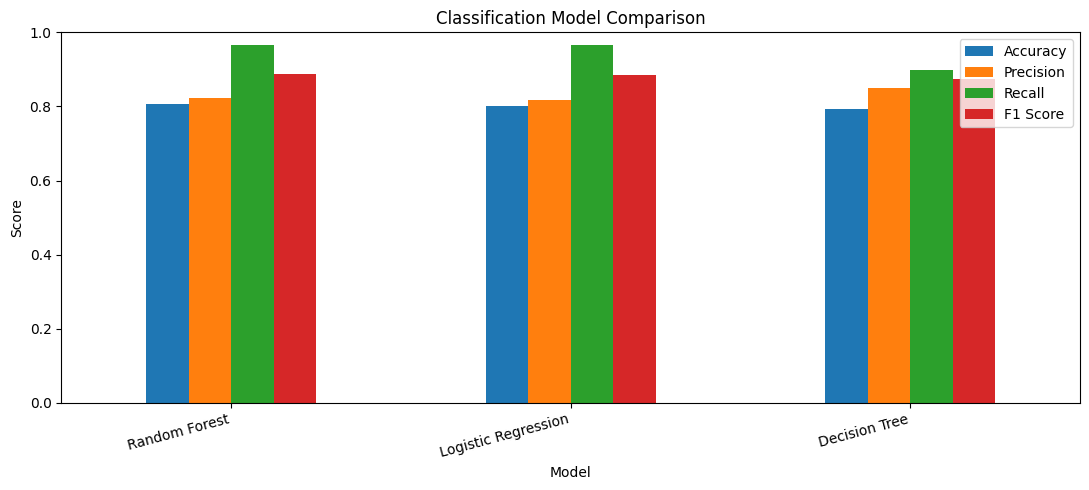

Best classifier by F1 score: Random Forest

Classification report:
              precision    recall  f1-score   support

           0       0.58      0.18      0.28        61
           1       0.82      0.97      0.89       239

    accuracy                           0.81       300
   macro avg       0.70      0.57      0.58       300
weighted avg       0.77      0.81      0.76       300



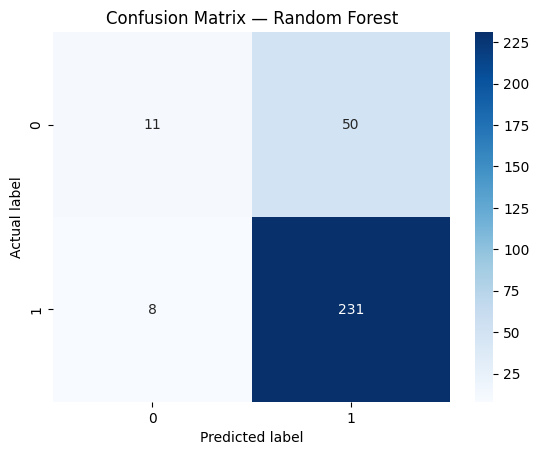

In [ ]:
# Visual comparison of classification metrics
classification_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1)
)
plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

best_classifier_name = classification_df.loc[0, "Model"]
best_classifier = trained_classifiers[best_classifier_name]
class_predictions = best_classifier.predict(X_test)

print("Best classifier by F1 score:", best_classifier_name)
print("\nClassification report:")
print(classification_report(y_class_test, class_predictions, zero_division=0))

cm = confusion_matrix(y_class_test, class_predictions)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix — {best_classifier_name}")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.show()


### Classification metrics
- **Accuracy:** fraction of all predictions that are correct.
- **Precision:** fraction of predicted purchases that were actual purchases.
- **Recall:** fraction of actual purchases correctly identified.
- **F1-score:** harmonic mean of precision and recall.
- **Confusion matrix:** counts true negatives, false positives, false negatives, and true positives.


## 6. Regression: train and compare models

In [ ]:
regressors = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=8, random_state=RANDOM_STATE
    )
}

regression_results = []
trained_regressors = {}

for name, model in regressors.items():
    pipeline = make_pipeline(preprocessor, model)
    pipeline.fit(X_train, y_reg_train)
    predictions = pipeline.predict(X_test)

    trained_regressors[name] = pipeline
    mse = mean_squared_error(y_reg_test, predictions)
    regression_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_reg_test, predictions),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_reg_test, predictions)
    })

regression_df = pd.DataFrame(regression_results).sort_values(
    "RMSE", ascending=True
).reset_index(drop=True)

display(regression_df.round(3))


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,78.875,10370.768,101.837,1.000
1,Random Forest,112.820,20068.328,141.663,0.999
2,Decision Tree,147.022,33195.808,182.197,0.999


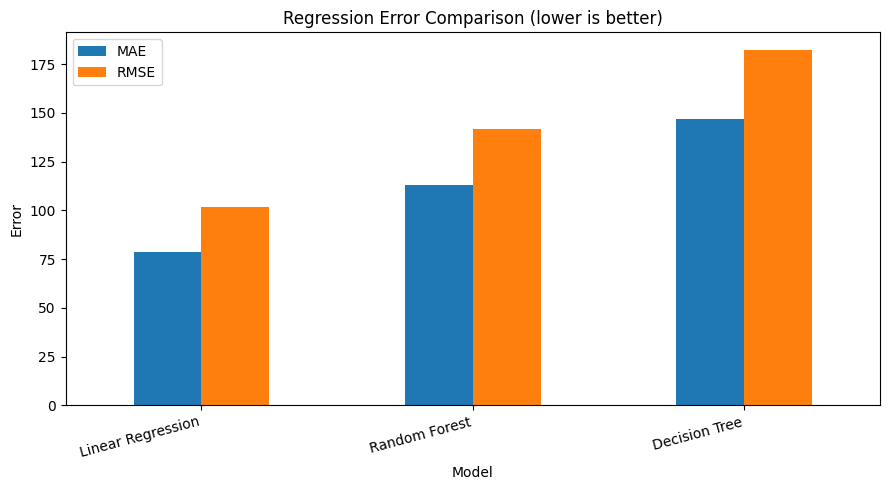

Best regressor by lowest RMSE: Linear Regression
R² score: 1.0


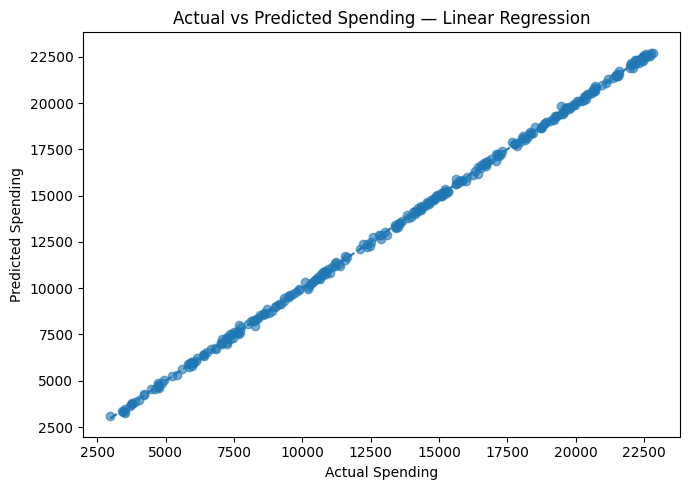

In [ ]:
regression_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Regression Error Comparison (lower is better)")
plt.ylabel("Error")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

best_regressor_name = regression_df.loc[0, "Model"]
best_regressor = trained_regressors[best_regressor_name]
reg_predictions = best_regressor.predict(X_test)

print("Best regressor by lowest RMSE:", best_regressor_name)
print("R² score:", round(r2_score(y_reg_test, reg_predictions), 3))

plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, reg_predictions, alpha=0.6)
low = min(y_reg_test.min(), reg_predictions.min())
high = max(y_reg_test.max(), reg_predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Spending")
plt.ylabel("Predicted Spending")
plt.title(f"Actual vs Predicted Spending — {best_regressor_name}")
plt.tight_layout()
plt.show()


### Regression metrics
- **MAE:** average absolute difference between actual and predicted spending.
- **MSE:** average squared prediction error.
- **RMSE:** square root of MSE, expressed in the target's units.
- **R²:** proportion of target variance explained by the model; it can be negative on test data.


## 7. Predict for a new customer

In [ ]:
new_customer = pd.DataFrame([{
    "age": 25,
    "annual_income": 65000,
    "website_visits": 12,
    "time_on_site": 15.5,
    "previous_purchases": 3,
    "discount_used": 1,
    "device": "Mobile"
}])

purchase_prediction = best_classifier.predict(new_customer)[0]
spending_prediction = best_regressor.predict(new_customer)[0]

print("New customer details:")
display(new_customer)
print("Predicted purchase:", "Yes" if purchase_prediction == 1 else "No")
print(f"Predicted spending: {spending_prediction:.2f}")


New customer details:


,age,annual_income,website_visits,time_on_site,previous_purchases,discount_used,device
0,25,65000,12,15.5,3,1,Mobile


Predicted purchase: Yes
Predicted spending: 9861.37




## 8. Conclusion

This activity demonstrates a complete machine-learning workflow for both classification and regression. Classification predicts a discrete customer purchase outcome, while regression predicts a continuous spending value. The models are compared using suitable metrics and visualizations. Since this notebook uses synthetic data, its results are useful for learning and demonstrating the workflow but should not be interpreted as real-world business findings.


